# 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import glob
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

SEED = 0
MODEL_NAME = "facebook/deit-tiny-patch16-224"
DATA_ROOT = "/content/drive/MyDrive/handgestures"          # folder containing train_val_<label> subfolders
CSV_PATH = "/content/drive/MyDrive/handgestures/processed_data_merged.csv"
CLASSES = ["call", "dislike", "fist", "four", "like"]
BATCH_SIZE = 8
NUM_WORKERS = 0
EPOCHS = 3

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(os.cpu_count())


# 2. Load CSV, locate image files

In [3]:
df = pd.read_csv(CSV_PATH)
df = df[df["label"].isin(CLASSES)].reset_index(drop=True)

def find_path(row):
    pattern = os.path.join(DATA_ROOT, f"train_val_{row['label']}", f"{row['id']}.*")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

df["path"] = df.apply(find_path, axis=1)
missing = df["path"].isna().sum()
print("missing files:", missing)
df = df.dropna(subset=["path"]).reset_index(drop=True)

label2id = {l: i for i, l in enumerate(CLASSES)}
id2label = {i: l for l, i in label2id.items()}
df["label_id"] = df["label"].map(label2id)
print(df.shape)
print(df["label"].value_counts())

missing files: 0
(5000, 9)
label
call       1000
dislike    1000
fist       1000
four       1000
like       1000
Name: count, dtype: int64


# 3. Stratified split 75/5/20

In [4]:
idx = np.arange(len(df))
y = df["label_id"].values

train_idx, temp_idx, y_train, y_temp = train_test_split(
    idx, y, test_size=0.25, random_state=SEED, stratify=y
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.80, random_state=SEED, stratify=y_temp
)

print("train:", len(train_idx), "val:", len(val_idx), "test:", len(test_idx))

df_train = df.iloc[train_idx].reset_index(drop=True)
df_val = df.iloc[val_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

train: 3750 val: 250 test: 1000


# 4. Export test set image ids

In [5]:
df_test[["id", "label"]].to_csv("test_set_ids.csv", index=False)
print("saved test_set_ids.csv:", len(df_test), "rows")

saved test_set_ids.csv: 1000 rows


# 5. Pre-process and cache all images once (avoids re-decoding every epoch)

In [6]:
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

def preprocess_split(df, batch_size=32):
    pixel_values_list = []
    for i in range(0, len(df), batch_size):
        chunk = df.iloc[i:i + batch_size]
        images = [Image.open(p).convert("RGB") for p in chunk["path"]]
        pv = processor(images=images, return_tensors="pt")["pixel_values"]
        pixel_values_list.append(pv)
        if i % (batch_size * 10) == 0:
            print(f"{i}/{len(df)}")
    pixel_values = torch.cat(pixel_values_list, dim=0)
    labels = torch.tensor(df["label_id"].values)
    return pixel_values, labels

t0 = time.time()
train_X, train_y = preprocess_split(df_train)
val_X, val_y = preprocess_split(df_val)
test_X, test_y = preprocess_split(df_test)
print(f"preprocessing done in {time.time()-t0:.1f}s")
print(train_X.shape, val_X.shape, test_X.shape)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

0/3750
320/3750
640/3750
960/3750
1280/3750
1600/3750
1920/3750
2240/3750
2560/3750
2880/3750
3200/3750
3520/3750
0/250
0/1000
320/1000
640/1000
960/1000
preprocessing done in 1894.4s
torch.Size([3750, 3, 224, 224]) torch.Size([250, 3, 224, 224]) torch.Size([1000, 3, 224, 224])


In [7]:
from torch.utils.data import TensorDataset

train_loader = DataLoader(TensorDataset(train_X, train_y), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(val_X, val_y), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(test_X, test_y), batch_size=BATCH_SIZE, shuffle=False)

# 6. Model: full fine-tune (all parameters trainable)

In [8]:
model = AutoModelForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(CLASSES),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"trainable params: {trainable}/{total}")

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 23.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-tiny-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([5])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 192]) vs model:torch.Size([5, 192])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


trainable params: 5525381/5525381


# 7. Train loop

In [9]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for pixel_values, labels in loader:
            if train:
                optimizer.zero_grad()
            out = model(pixel_values=pixel_values).logits
            loss = criterion(out, labels)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (out.argmax(1) == labels).sum().item()
            n += labels.size(0)
    return total_loss / n, correct / n

for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    print(f"epoch {epoch+1}/{EPOCHS} | train_loss {train_loss:.3f} acc {train_acc:.3f} "
          f"| val_loss {val_loss:.3f} acc {val_acc:.3f} | {time.time()-t0:.1f}s")

epoch 1/3 | train_loss 1.018 acc 0.586 | val_loss 0.504 acc 0.832 | 595.6s
epoch 2/3 | train_loss 0.292 acc 0.902 | val_loss 0.397 acc 0.840 | 530.3s
epoch 3/3 | train_loss 0.096 acc 0.976 | val_loss 0.482 acc 0.840 | 528.1s


# 8. Evaluate on held-out test set

In [10]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for pixel_values, labels in test_loader:
        out = model(pixel_values=pixel_values).logits
        all_preds.extend(out.argmax(1).tolist())
        all_labels.extend(labels.tolist())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print("test accuracy:", accuracy_score(all_labels, all_preds))
print(classification_report(all_labels, all_preds, target_names=CLASSES))

test accuracy: 0.871
              precision    recall  f1-score   support

        call       0.87      0.85      0.86       200
     dislike       0.89      0.94      0.91       200
        fist       0.86      0.85      0.85       200
        four       0.91      0.93      0.92       200
        like       0.81      0.79      0.80       200

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000



# 9. Confusion matrix

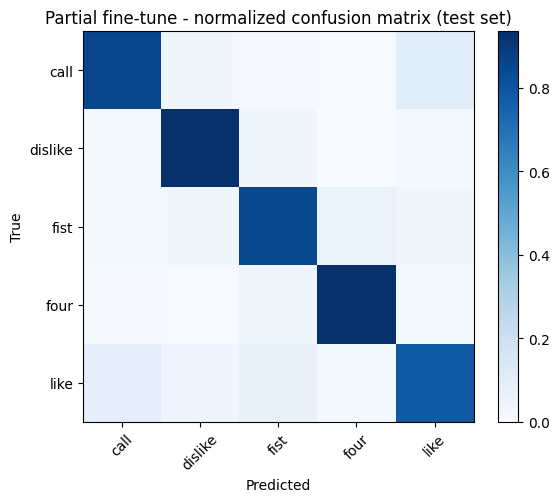

In [11]:
cm = confusion_matrix(all_labels, all_preds, normalize="true")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)))
ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=45)
ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Partial fine-tune - normalized confusion matrix (test set)")
fig.colorbar(im)
plt.tight_layout()
plt.show()

# 10. Save model weights + test predictions

In [12]:
model.save_pretrained("deit_tiny_5class_finetuned")
processor.save_pretrained("deit_tiny_5class_finetuned")

np.savez("test_predictions.npz", y_true=all_labels, y_pred=all_preds,
         test_ids=df_test["id"].values)

print("saved model to deit_tiny_5class_finetuned/ and test_predictions.npz")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved model to deit_tiny_5class_finetuned/ and test_predictions.npz


In [13]:
df_train[["id", "label"]].to_csv("train_set_ids.csv", index=False)
df_val[["id", "label"]].to_csv("val_set_ids.csv", index=False)

In [14]:
import torch.nn.functional as F


model.eval()
all_probs, all_preds, all_labels = [], [], []
with torch.no_grad():
    for pixel_values, labels in test_loader:
        logits = model(pixel_values=pixel_values).logits
        probs = F.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_preds.extend(probs.argmax(1).tolist())
        all_labels.extend(labels.tolist())

all_probs = np.concatenate(all_probs, axis=0)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

In [15]:
results = pd.DataFrame({
    "id": df_test["id"].values,
    "true_label": [CLASSES[i] for i in all_labels],
    "pred_label": [CLASSES[i] for i in all_preds],
    "confidence": all_probs.max(axis=1),
    "correct": all_preds == all_labels,
})

misclassified = results[~results["correct"]].sort_values("confidence", ascending=False)
correct = results[results["correct"]]

results.to_csv("test_results_full.csv", index=False)
misclassified.to_csv("test_results_misclassified.csv", index=False)

In [17]:
prob_cols = {f"prob_{cls}": all_probs[:, i] for i, cls in enumerate(CLASSES)}
results_all = pd.DataFrame({
    "id": df_test["id"].values,
    "true_label": [CLASSES[i] for i in all_labels],
    "pred_label": [CLASSES[i] for i in all_preds],
    **prob_cols,
    "confidence": all_probs.max(axis=1),
    "correct": all_preds == all_labels,
})

results_all.to_csv("test_all_probs.csv", index=False)

In [18]:
embeddings = []
with torch.no_grad():
    for pixel_values, labels in test_loader:
        out = model.vit(pixel_values=pixel_values).last_hidden_state[:, 0, :]
        embeddings.append(out.cpu().numpy())
embeddings = np.concatenate(embeddings, axis=0)
np.savez("test_embeddings.npz", embeddings=embeddings, labels=all_labels, ids=df_test["id"].values)

In [19]:
all_logits = []
with torch.no_grad():
    for pixel_values, labels in test_loader:
        all_logits.append(model(pixel_values=pixel_values).logits.cpu().numpy())
all_logits = np.concatenate(all_logits, axis=0)
np.savez("test_logits.npz", logits=all_logits, labels=all_labels, ids=df_test["id"].values)